# 05 · Desenvolvimento econômico: o PIB per capita explica o progresso social na RMBH?

Segunda parte da Pergunta 2. O IPS não inclui variáveis econômicas; o PIB per capita vem na base como informação complementar.

> Parte 5 de 6 do projeto *BH e Região sob a perspectiva dos dados*. Veja o [README](../README.md) para a visão geral.

In [1]:
# Configuração: funciona no computador (a partir da pasta notebooks/) e no Google Colab
import os
import subprocess
import sys
from pathlib import Path

if 'google.colab' in sys.modules:
    repo = Path('/content/ips-bh-rmbh')
    if not repo.exists():
        subprocess.run(['git', 'clone', '-q', 'https://github.com/millebns/ips-bh-rmbh.git', str(repo)], check=True)
    os.chdir(repo / 'notebooks')

sys.path.insert(0, str(Path.cwd().parent / 'src'))

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from functools import partial

from ips_rmbh import analise
from ips_rmbh.config import BH, COR_BH, COR_OUTROS, COR_DESTAQUE, PASTA_FIGURAS
from ips_rmbh.dados import carregar_rmbh

df_rmbh = carregar_rmbh()

# Atalhos que comparam BH com os demais municípios da RMBH
posicao_bh = partial(analise.posicao, df_rmbh)
valor_bh = partial(analise.valor, df_rmbh)
print(df_rmbh.shape)

(34, 78)


In [3]:
log_pib = np.log10(df_rmbh['PIB PER CAPITA'])
coef = np.polyfit(log_pib, df_rmbh['Índice de Progresso Social'], 1)
df_rmbh['ips_esperado'] = np.polyval(coef, log_pib)
df_rmbh['diferenca_esperado'] = df_rmbh['Índice de Progresso Social'] - df_rmbh['ips_esperado']

print(f"Correlação entre IPS e log(PIB per capita): {np.corrcoef(log_pib, df_rmbh['Índice de Progresso Social'])[0, 1]:.2f}")
print(f"Posição de BH em PIB per capita: {posicao_bh('PIB PER CAPITA')}º de 34")


Correlação entre IPS e log(PIB per capita): 0.49
Posição de BH em PIB per capita: 8º de 34


In [4]:
(df_rmbh[['Município', 'PIB PER CAPITA', 'Índice de Progresso Social', 'diferenca_esperado']]
 .sort_values('diferenca_esperado', ascending=False)
 .round(2)
 .reset_index(drop=True))

,Município,PIB PER CAPITA,Índice de Progresso Social,diferenca_esperado
0,Nova Lima,102907.19,71.22,4.84
1,Belo Horizonte,53892.62,69.66,4.70
2,Sarzedo,41089.76,68.47,4.11
3,Florestal,21597.47,65.98,3.03
4,Ibirité,18017.57,65.43,2.87
5,Rio Acima,24337.45,66.04,2.82
6,Igarapé,28538.76,65.77,2.21
7,Caeté,25245.28,65.39,2.09
8,Contagem,69190.04,67.57,2.06
9,Mário Campos,14395.51,63.91,1.85


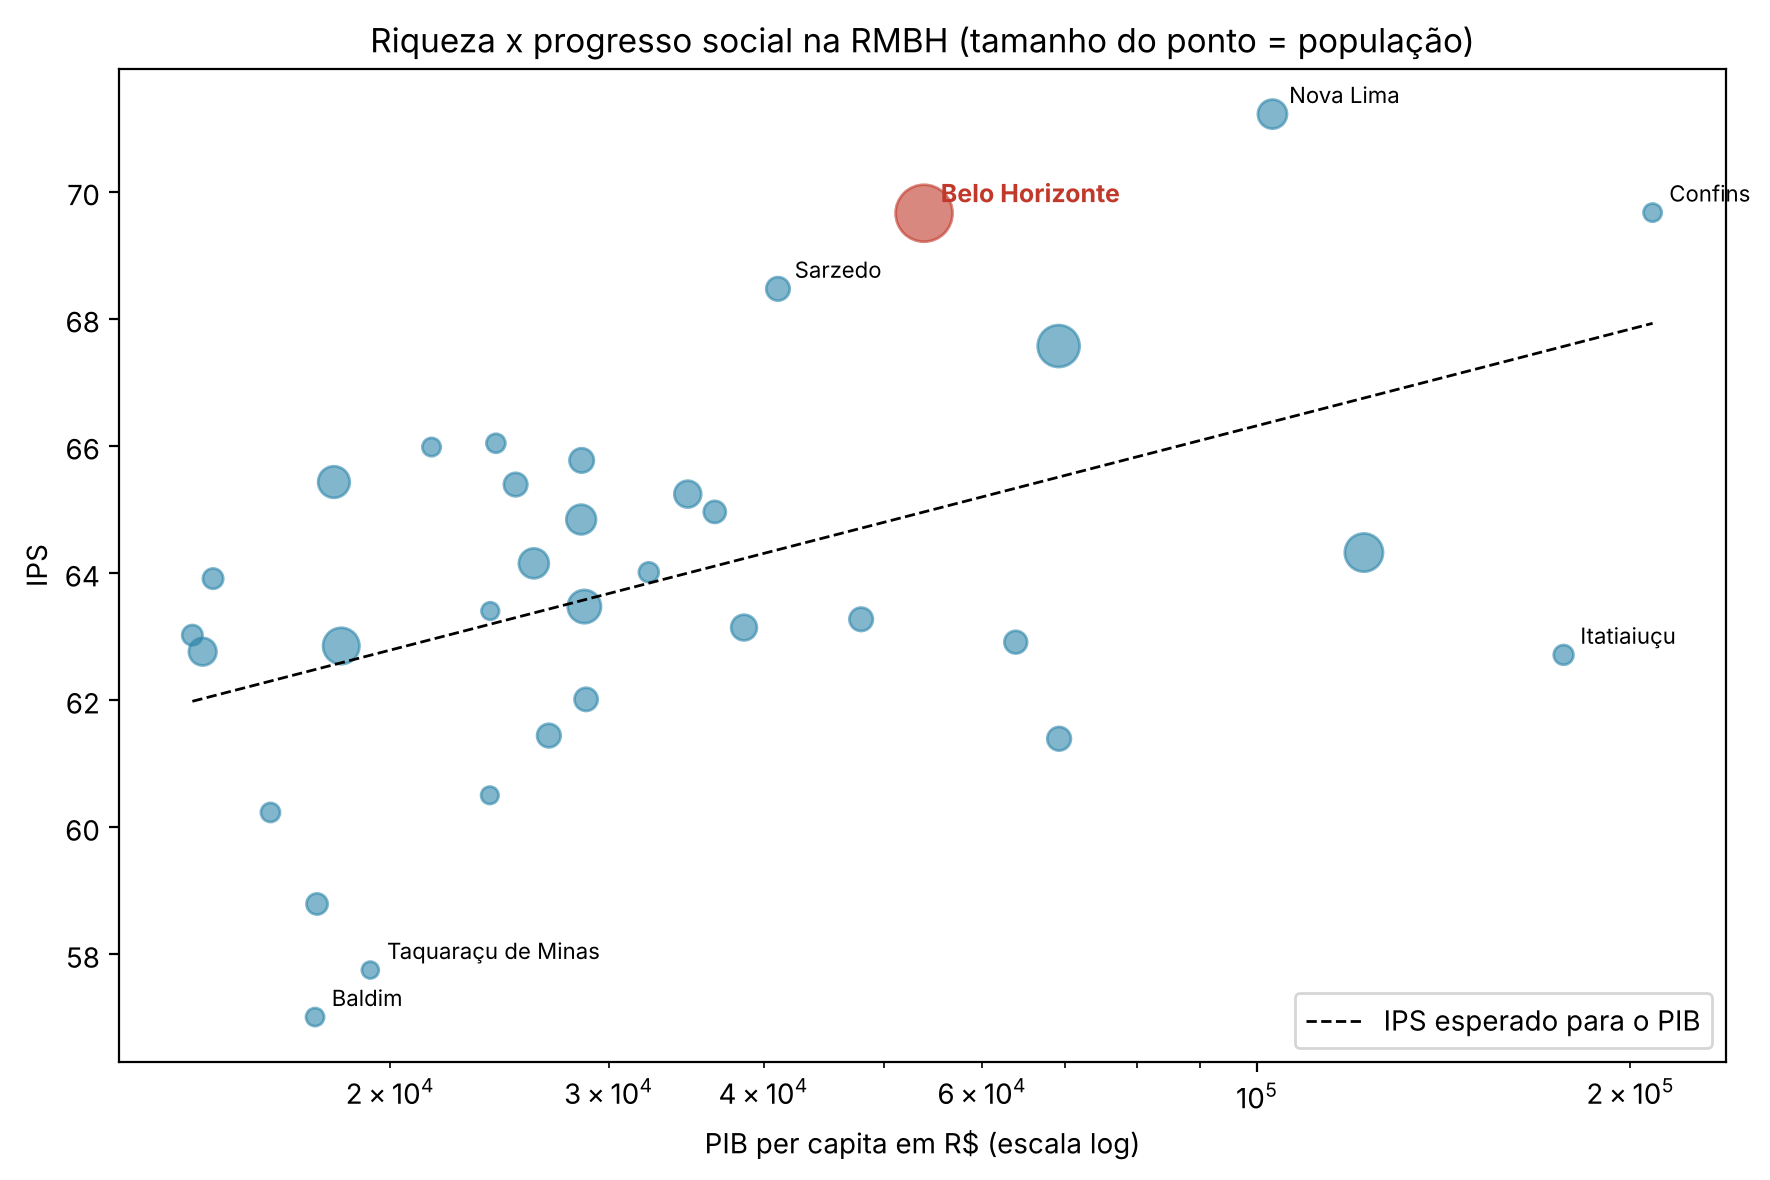

In [5]:
destaques = ['Belo Horizonte', 'Nova Lima', 'Confins', 'Sarzedo', 'Itatiaiuçu', 'Baldim', 'Taquaraçu de Minas']
tamanho = 20 + 400 * (df_rmbh['POPULAÇÃO 2025'] / df_rmbh['POPULAÇÃO 2025'].max()) ** 0.5

fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(df_rmbh['PIB PER CAPITA'], df_rmbh['Índice de Progresso Social'], s=tamanho, alpha=0.6,
           c=[COR_BH if m == BH else '#2E86AB' for m in df_rmbh['Município']])
xs = np.linspace(log_pib.min(), log_pib.max(), 50)
ax.plot(10 ** xs, np.polyval(coef, xs), c='black', lw=1, ls='--', label='IPS esperado para o PIB')
for _, r in df_rmbh[df_rmbh['Município'].isin(destaques)].iterrows():
    eh_bh = r['Município'] == BH
    ax.annotate(r['Município'], (r['PIB PER CAPITA'], r['Índice de Progresso Social']),
                xytext=(6, 4), textcoords='offset points', fontsize=9 if eh_bh else 8,
                fontweight='bold' if eh_bh else 'normal', color=COR_BH if eh_bh else 'black')
ax.set_xscale('log')
ax.set_xlabel('PIB per capita em R$ (escala log)')
ax.set_ylabel('IPS')
ax.set_title('Riqueza x progresso social na RMBH (tamanho do ponto = população)')
ax.legend(loc='lower right')
plt.tight_layout()
plt.savefig(PASTA_FIGURAS / '03_ips_x_pib.png', dpi=150, bbox_inches='tight')
plt.show()

A relação entre riqueza e progresso social é moderada (correlação de 0,49 com o log do PIB per capita). BH está entre os municípios com IPS acima do esperado para o seu PIB, junto com Nova Lima e Sarzedo. Já Itatiaiuçu tem um dos maiores PIB per capita da região e IPS abaixo da mediana.

Resposta: em qualidade de vida, BH se destaca em educação superior, direitos e saneamento, mas é a última da região em inclusão social, principalmente pela população em situação de rua. Em desenvolvimento econômico, BH converte sua riqueza em progresso social acima do esperado.

**Próximo notebook:** [06 · Segurança](06_seguranca.ipynb)